# Monte Carlo Simulation Analysis

This notebook uses the reusable tools in `src/` to visualise GBM simulations and compare them against closed-form results.
Everything here is **model-only** (no market data yet). The sections map onto the planned Streamlit app:

1. **Spaghetti plot**: 1,000 GBM paths and how dispersion grows over time
2. **Terminal histogram**: 10,000 terminal prices against the theoretical lognormal density
3. **Option valuation engine**: Monte Carlo vs Black–Scholes, confidence intervals, convergence, and a mispricing-flag scaffold
4. **Risk assessment**: Monte Carlo portfolio VaR / CVaR checked against the analytic answer

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Make the repository-level src package importable whether the kernel starts
# in the project root or in the notebooks directory.
project_root = Path.cwd().resolve()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import (
    black_scholes_call,
    black_scholes_put,
    compare_call_prices,
    compare_put_prices,
    monte_carlo_call_price,
    monte_carlo_put_price,
    simulate_gbm_paths,
    simulate_terminal_prices,
)

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 0. Parameters

One place to change the market assumptions. Later these will come from live data:
$S_0$ from the spot price, $\sigma$ from historical or implied volatility, and $r$ from a treasury yield.

In [2]:
S0 = 100.0        # spot price
r = 0.05          # annual risk-free rate
sigma = 0.35      # annual volatility
T = 1.0           # horizon in years
N_STEPS = 252     # one step per trading day
SEED = 42

N_PATHS_SPAGHETTI = 1_000
N_TERMINAL = 10_000

time_grid = np.linspace(0.0, T, N_STEPS + 1)

## 1. Spaghetti Plot: 1,000 GBM Paths

Under the risk-neutral measure each path follows

$$dS_t = r S_t\,dt + \sigma S_t\,dW_t \quad\Longrightarrow\quad S_t = S_0\, e^{(r-\frac12\sigma^2)t + \sigma W_t}.$$

Picture a fan opening up. Every path starts at $S_0$, and the spread grows with $\sqrt{t}$.
The shaded bands are the simulated 5–95% and 25–75% ranges. The dashed line is the theoretical mean $S_0 e^{rt}$.

paths shape: (1000, 253)


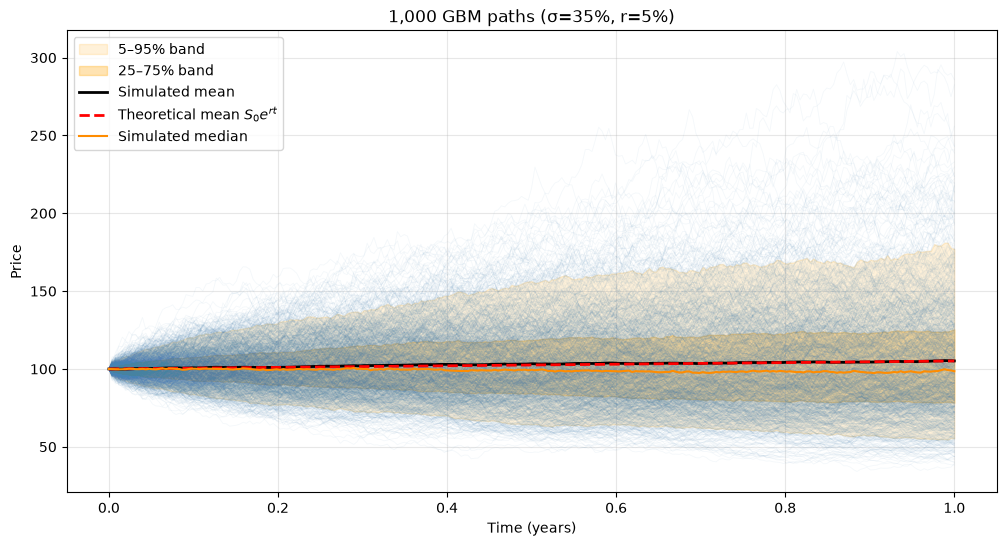

In [3]:
paths = simulate_gbm_paths(S0, r, sigma, T, N_STEPS, N_PATHS_SPAGHETTI, rng=np.random.default_rng(SEED))
print("paths shape:", paths.shape)  # (n_paths, n_steps + 1)

p05, p25, p50, p75, p95 = np.percentile(paths, [5, 25, 50, 75, 95], axis=0)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(time_grid, paths.T, color="steelblue", alpha=0.06, linewidth=0.6)
ax.fill_between(time_grid, p05, p95, color="orange", alpha=0.15, label="5–95% band")
ax.fill_between(time_grid, p25, p75, color="orange", alpha=0.30, label="25–75% band")
ax.plot(time_grid, paths.mean(axis=0), color="black", linewidth=2, label="Simulated mean")
ax.plot(time_grid, S0 * np.exp(r * time_grid), "r--", linewidth=2, label=r"Theoretical mean $S_0e^{rt}$")
ax.plot(time_grid, p50, color="darkorange", linewidth=1.5, label="Simulated median")
ax.set(xlabel="Time (years)", ylabel="Price", title=f"{N_PATHS_SPAGHETTI:,} GBM paths (σ={sigma:.0%}, r={r:.0%})")
ax.legend(loc="upper left")
plt.show()

### Volatility expansion

Two ways to see the fan widening, each compared with its closed form:

- **Log-price dispersion:** $\operatorname{sd}(\ln S_t) = \sigma\sqrt{t}$. This is the "pure" volatility and grows like a square root.
- **Price dispersion:** $\operatorname{sd}(S_t) = S_0 e^{rt}\sqrt{e^{\sigma^2 t}-1}$. This grows faster than a square root because of the lognormal skew.

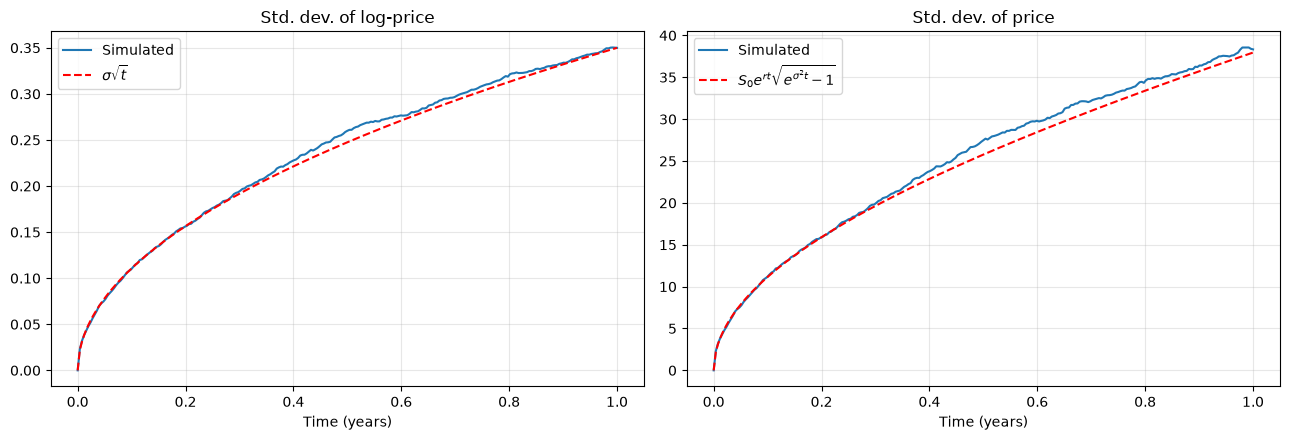

In [4]:
sim_log_sd = np.log(paths).std(axis=0, ddof=1)
sim_price_sd = paths.std(axis=0, ddof=1)
theo_log_sd = sigma * np.sqrt(time_grid)
theo_price_sd = S0 * np.exp(r * time_grid) * np.sqrt(np.exp(sigma**2 * time_grid) - 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(time_grid, sim_log_sd, label="Simulated")
ax1.plot(time_grid, theo_log_sd, "r--", label=r"$\sigma\sqrt{t}$")
ax1.set(title="Std. dev. of log-price", xlabel="Time (years)")
ax1.legend()
ax2.plot(time_grid, sim_price_sd, label="Simulated")
ax2.plot(time_grid, theo_price_sd, "r--", label=r"$S_0e^{rt}\sqrt{e^{\sigma^2t}-1}$")
ax2.set(title="Std. dev. of price", xlabel="Time (years)")
ax2.legend()
plt.tight_layout()
plt.show()

## 2. Terminal Histogram: 10,000 Runs

Because $\ln S_T \sim \mathcal N\!\big(\ln S_0 + (r-\tfrac12\sigma^2)T,\ \sigma^2T\big)$, the terminal price is **lognormal**.
`simulate_terminal_prices` samples $S_T$ in one step without building paths, which is much cheaper.

Three "centres" separate in a skewed distribution:
**mode < median < mean**. The peak (most likely single value) sits *below* the mean,
while a long right tail pulls the mean up. The red shaded areas are the extreme 1% tails on each side.

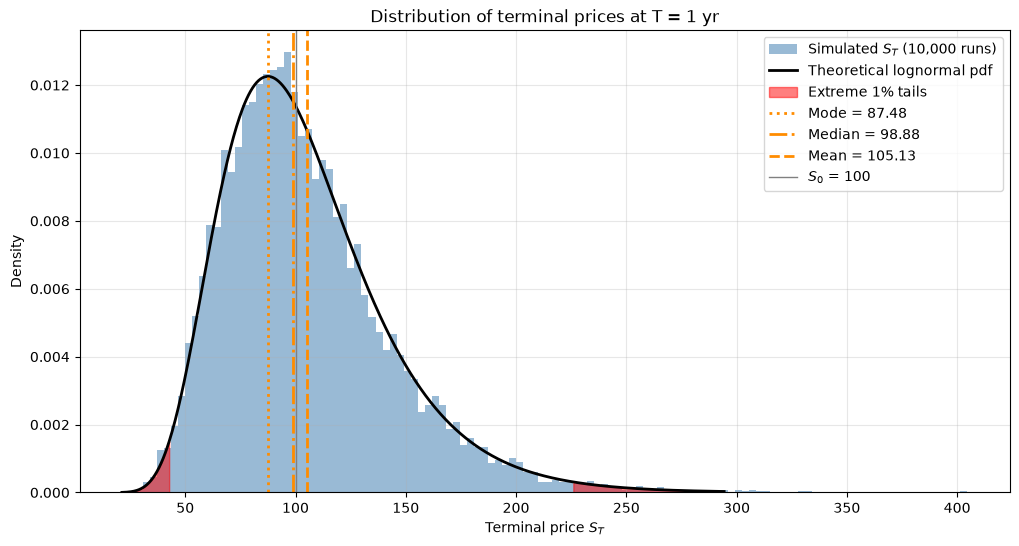

In [5]:
ST = simulate_terminal_prices(S0, r, sigma, T, N_TERMINAL, rng=np.random.default_rng(SEED))

# Theoretical lognormal: scipy parameterisation s = sigma*sqrt(T), scale = exp(mean of ln S_T)
s_ln = sigma * np.sqrt(T)
scale_ln = S0 * np.exp((r - 0.5 * sigma**2) * T)
lognormal = stats.lognorm(s=s_ln, scale=scale_ln)

theo_mode = scale_ln * np.exp(-s_ln**2)
theo_median = scale_ln
theo_mean = S0 * np.exp(r * T)
q01, q99 = np.quantile(ST, [0.01, 0.99])

x = np.linspace(ST.min(), np.quantile(ST, 0.999), 600)
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(ST, bins=120, density=True, color="steelblue", alpha=0.55, label=f"Simulated $S_T$ ({N_TERMINAL:,} runs)")
ax.plot(x, lognormal.pdf(x), "k", linewidth=2, label="Theoretical lognormal pdf")
ax.fill_between(x, lognormal.pdf(x), where=x <= q01, color="red", alpha=0.5, label="Extreme 1% tails")
ax.fill_between(x, lognormal.pdf(x), where=x >= q99, color="red", alpha=0.5)
for value, name, style in [(theo_mode, "Mode", ":"), (theo_median, "Median", "-."), (theo_mean, "Mean", "--")]:
    ax.axvline(value, color="darkorange", linestyle=style, linewidth=2, label=f"{name} = {value:.2f}")
ax.axvline(S0, color="grey", linewidth=1, label=f"$S_0$ = {S0:.0f}")
ax.set(xlabel="Terminal price $S_T$", ylabel="Density", title=f"Distribution of terminal prices at T = {T:g} yr")
ax.legend()
plt.show()

In [6]:
def _prob_below(level):
    return float(np.mean(ST < level)), float(lognormal.cdf(level))

rows = {
    "Mean": (ST.mean(), lognormal.mean()),
    "Median": (np.median(ST), lognormal.median()),
    "Std. dev.": (ST.std(ddof=1), lognormal.std()),
    "Skewness": (stats.skew(ST), float(lognormal.stats(moments="s"))),
    "1% quantile": (q01, lognormal.ppf(0.01)),
    "99% quantile": (q99, lognormal.ppf(0.99)),
    "P(S_T < 0.7·S0)  (30%+ drop)": _prob_below(0.7 * S0),
    "P(S_T < 0.5·S0)  (halved)": _prob_below(0.5 * S0),
    "P(S_T > 1.5·S0)  (50%+ gain)": tuple(1 - p for p in _prob_below(1.5 * S0)),
}
terminal_summary = pd.DataFrame(rows, index=["Simulated", "Theoretical"]).T
terminal_summary["Difference"] = terminal_summary["Simulated"] - terminal_summary["Theoretical"]
terminal_summary

,Simulated,Theoretical,Difference
Mean,104.8325,105.1271,-0.2947
Median,98.4266,98.8813,-0.4547
Std. dev.,38.1440,37.9506,0.1934
Skewness,1.1599,1.1300,0.0299
1% quantile,43.0812,43.8028,-0.7216
99% quantile,225.5326,223.2165,2.3161
P(S_T < 0.7·S0) (30%+ drop),0.1682,0.1618,0.0064
P(S_T < 0.5·S0) (halved),0.0264,0.0257,0.0007
P(S_T > 1.5·S0) (50%+ gain),0.1165,0.1169,-0.0004


**Q–Q check.** If the simulation is right, $\ln S_T$ should be exactly normal, so the points should sit on the straight line.

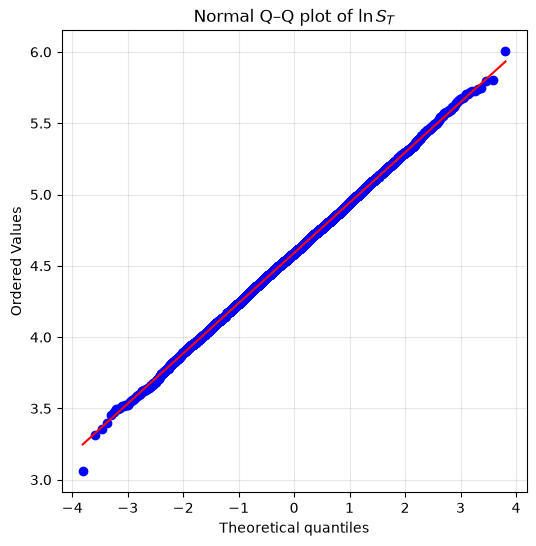

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(np.log(ST), dist="norm", plot=ax)
ax.set_title(r"Normal Q–Q plot of $\ln S_T$")
plt.show()

## 3. Option Valuation Engine

### 3.1 One option: price with a confidence interval

A Monte Carlo price is a *sample average* of discounted payoffs, so it comes with a standard error:

$$\hat V = e^{-rT}\frac1N\sum_i \text{payoff}(S_T^{(i)}),\qquad \text{SE} = e^{-rT}\frac{\operatorname{sd}(\text{payoff})}{\sqrt N}.$$

`compare_call_prices` / `compare_put_prices` give the MC and Black–Scholes prices. The helper below adds the SE and a 95% CI,
so we can tell whether a gap is real or just noise.

In [8]:
def mc_price_with_ci(terminal_prices, strike, T, r, s0, sigma, kind="call", z=1.96):
    """MC price, standard error, 95% CI and Black-Scholes benchmark for one European option."""
    if kind == "call":
        result = compare_call_prices(terminal_prices, s0, strike, T, r, sigma)
        payoff = np.maximum(terminal_prices - strike, 0.0)
    elif kind == "put":
        result = compare_put_prices(terminal_prices, s0, strike, T, r, sigma)
        payoff = np.maximum(strike - terminal_prices, 0.0)
    else:
        raise ValueError("kind must be 'call' or 'put'")

    se = float(np.exp(-r * T) * payoff.std(ddof=1) / np.sqrt(payoff.size))
    mc = result["monte_carlo_price"]
    bs = result["black_scholes_price"]
    return {
        "kind": kind,
        "strike": strike,
        "mc_price": mc,
        "bs_price": bs,
        "std_error": se,
        "ci_low": mc - z * se,
        "ci_high": mc + z * se,
        "abs_diff": result["absolute_difference"],
        "z_score": (mc - bs) / se if se > 0 else np.nan,
        "bs_in_ci": mc - z * se <= bs <= mc + z * se,
    }


pd.DataFrame([
    mc_price_with_ci(ST, 100, T, r, S0, sigma, "call"),
    mc_price_with_ci(ST, 100, T, r, S0, sigma, "put"),
]).set_index("kind")

,strike,mc_price,bs_price,std_error,ci_low,ci_high,abs_diff,z_score,bs_in_ci
kind,,,,,,,,,
call,100,15.9738,16.1284,0.2693,15.4461,16.5016,0.1546,-0.5741,True
put,100,11.3771,11.2514,0.1510,11.0811,11.6730,0.1257,0.8325,True


### 3.2 Across the strike range

Here we price calls and puts from deep in-the-money to deep out-of-the-money using the **same** 10,000 terminal prices.
The error bars are the 95% CIs. The right-hand panel shows the error measured in standard errors:
most points should land inside ±1.96.

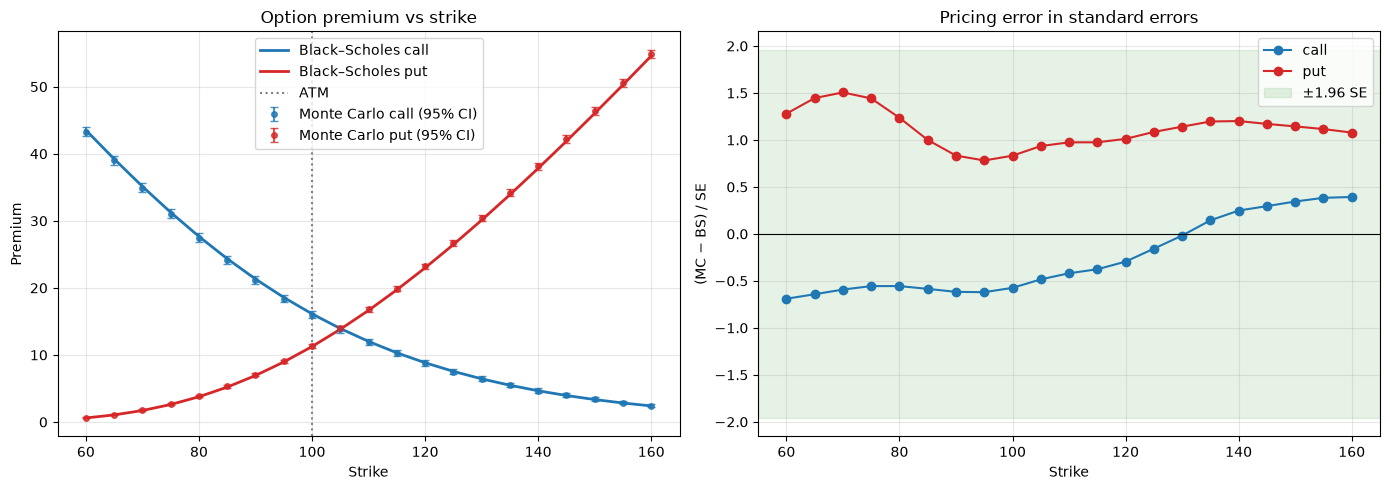

BS price inside the MC 95% CI for 100% of 42 options


mc_price         bs_price         std_error       
kind         call     put     call     put      call    put
strike                                                     
60.0000   43.2863  0.6403  43.5305  0.6043    0.3540 0.0282
65.0000   39.0040  1.1142  39.2278  1.0577    0.3485 0.0391
70.0000   34.9258  1.7921  35.1279  1.7139    0.3412 0.0519
75.0000   31.0807  2.7031  31.2652  2.6074    0.3323 0.0664
80.0000   27.4876  3.8663  27.6664  3.7647    0.3219 0.0821
85.0000   24.1674  5.3022  24.3489  5.2034    0.3102 0.0988
90.0000   21.1376  7.0286  21.3211  6.9318    0.2974 0.1161
95.0000   18.4074  9.0545  18.5833  8.9501    0.2837 0.1336
100.0000  15.9738 11.3771  16.1284 11.2514    0.2693 0.1510
105.0000  13.8210 13.9804  13.9442 13.8233    0.2545 0.1680
110.0000  11.9137 16.8293  12.0141 16.6493    0.2397 0.1846
115.0000  10.2345 19.9061  10.3192 19.7105    0.2251 0.2006
120.0000   8.7768 23.2046   8.8389 22.9865    0.2107 0.2157
125.0000   7.5217 26.7056   7.5526 26.4563    0.1967 0.2297
130.0000   6.4364 30.3765   6.4396 30.0994    0.1833 0.2428
135.0000   5.5050 34.2012   5.4804 33.8963    0.1704 0.2549
140.0000   4.6957 38.1481   4.6564 37.8285    0.1582 0.2661
145.0000   3.9941 42.2027   3.9508 41.8790    0.1466 0.2765
150.0000   3.3949 46.3596   3.3480 46.0324    0.1358 0.2859
155.0000   2.8826 50.6035   2.8344 50.2750    0.1256 0.2944
160.0000   2.4432 54.9202   2.3975 54.5942    0.1161 0.3022

In [9]:
strikes = np.arange(60, 165, 5)
chain = pd.DataFrame(
    [mc_price_with_ci(ST, float(k), T, r, S0, sigma, kind) for kind in ("call", "put") for k in strikes]
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for kind, color in [("call", "tab:blue"), ("put", "tab:red")]:
    sub = chain[chain.kind == kind]
    ax1.plot(sub.strike, sub.bs_price, color=color, linewidth=2, label=f"Black–Scholes {kind}")
    ax1.errorbar(sub.strike, sub.mc_price, yerr=1.96 * sub.std_error, fmt="o", color=color,
                 markersize=4, capsize=3, alpha=0.8, label=f"Monte Carlo {kind} (95% CI)")
    ax2.plot(sub.strike, sub.z_score, "o-", color=color, label=kind)
ax1.axvline(S0, color="grey", linestyle=":", label="ATM")
ax1.set(xlabel="Strike", ylabel="Premium", title="Option premium vs strike")
ax1.legend()
ax2.axhspan(-1.96, 1.96, color="green", alpha=0.1, label="±1.96 SE")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set(xlabel="Strike", ylabel="(MC − BS) / SE", title="Pricing error in standard errors")
ax2.legend()
plt.tight_layout()
plt.show()

print(f"BS price inside the MC 95% CI for {chain.bs_in_ci.mean():.0%} of {len(chain)} options")
chain.pivot(index="strike", columns="kind", values=["mc_price", "bs_price", "std_error"]).round(4)

A note on the right-hand panel: calls and puts at the same strike use the same random draws, so their errors are **correlated**.
Read it as one sample of noise, not 42 independent ones.

### 3.3 Convergence: how many simulations is "enough"?

Monte Carlo error shrinks like $1/\sqrt N$: you need **4× the runs to halve the error**.
We reprice the ATM call over 20 independent seeds at each $N$, up to 10,000 runs.

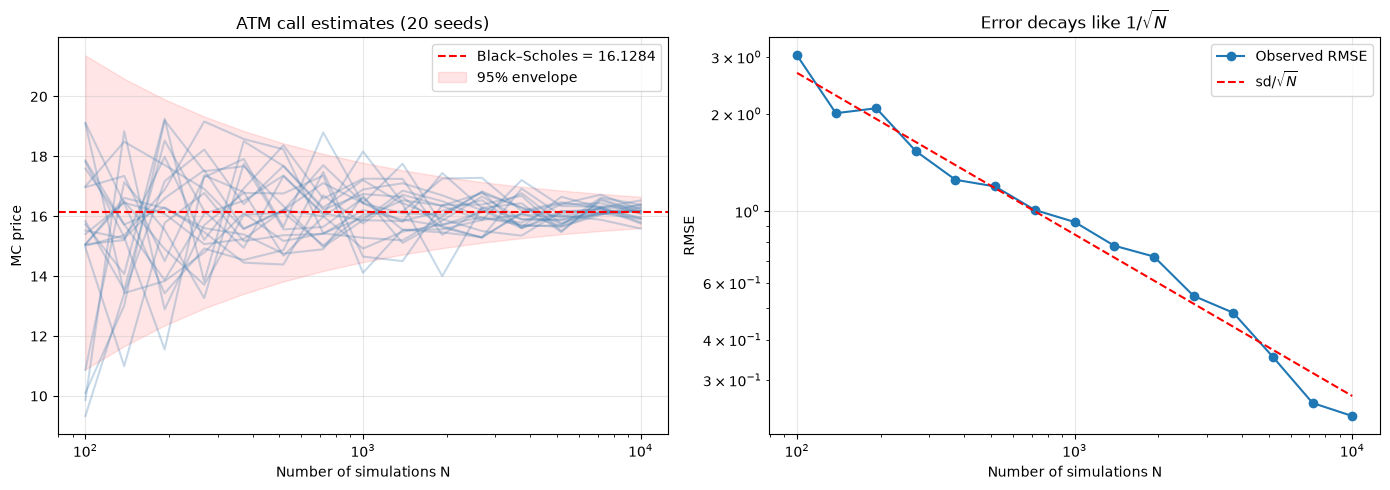

In [10]:
K_ATM = 100.0
bs_atm_call = black_scholes_call(S0, K_ATM, T, r, sigma)
n_grid = np.unique(np.logspace(2, 4, 15).astype(int))   # 100 ... 10,000
n_seeds = 20

errors = np.empty((len(n_grid), n_seeds))
for i, n in enumerate(n_grid):
    for j in range(n_seeds):
        st = simulate_terminal_prices(S0, r, sigma, T, n, rng=np.random.default_rng(1_000 * i + j))
        errors[i, j] = monte_carlo_call_price(st, K_ATM, T, r) - bs_atm_call

rmse = np.sqrt((errors**2).mean(axis=1))
# Theoretical RMSE = sd(discounted payoff) / sqrt(N), using a large reference sample
ref = simulate_terminal_prices(S0, r, sigma, T, 200_000, rng=np.random.default_rng(7))
payoff_sd = np.exp(-r * T) * np.maximum(ref - K_ATM, 0).std()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for j in range(n_seeds):
    ax1.plot(n_grid, bs_atm_call + errors[:, j], color="steelblue", alpha=0.3)
ax1.axhline(bs_atm_call, color="red", linestyle="--", label=f"Black–Scholes = {bs_atm_call:.4f}")
ax1.fill_between(n_grid, bs_atm_call - 1.96 * payoff_sd / np.sqrt(n_grid),
                 bs_atm_call + 1.96 * payoff_sd / np.sqrt(n_grid), color="red", alpha=0.1, label="95% envelope")
ax1.set(xscale="log", xlabel="Number of simulations N", ylabel="MC price", title=f"ATM call estimates ({n_seeds} seeds)")
ax1.legend()
ax2.loglog(n_grid, rmse, "o-", label="Observed RMSE")
ax2.loglog(n_grid, payoff_sd / np.sqrt(n_grid), "r--", label=r"$\mathrm{sd}/\sqrt{N}$")
ax2.set(xlabel="Number of simulations N", ylabel="RMSE", title="Error decays like $1/\\sqrt{N}$")
ax2.legend()
plt.tight_layout()
plt.show()

### 3.4 Sanity check: put–call parity

For European options, $C - P = S_0 - Ke^{-rT}$ holds *exactly*, whatever the model.
On a simulated sample the gap equals the sampling error in $\bar S_T$. That gives a cheap way to test the simulator.

In [11]:
parity = pd.DataFrame({
    "strike": strikes,
    "MC  C - P": [monte_carlo_call_price(ST, k, T, r) - monte_carlo_put_price(ST, k, T, r) for k in strikes],
    "BS  C - P": [black_scholes_call(S0, k, T, r, sigma) - black_scholes_put(S0, k, T, r, sigma) for k in strikes],
    "S0 - K e^{-rT}": S0 - strikes * np.exp(-r * T),
}).set_index("strike")
print("Discounted mean of S_T minus S0 (pure sampling noise):", np.exp(-r * T) * ST.mean() - S0)
parity.head(8)

Discounted mean of S_T minus S0 (pure sampling noise): -0.28028367055858894


,MC C - P,BS C - P,S0 - K e^{-rT}
strike,,,
60,42.6460,42.9262,42.9262
65,37.8898,38.1701,38.1701
70,33.1337,33.4139,33.4139
75,28.3775,28.6578,28.6578
80,23.6214,23.9016,23.9016
85,18.8652,19.1455,19.1455
90,14.1091,14.3894,14.3894
95,9.3529,9.6332,9.6332


### 3.5 Mispricing flag: scaffold for live data

This is the logic the Streamlit engine will run once real quotes are pulled in. An option is flagged only if the market price
sits outside a **tolerance band** around the model price. The band is the larger of:

- the Monte Carlo noise ($z \times \text{SE}$), so we never flag simulation error, and
- a relative threshold (default 5%), so tiny absolute gaps on cheap options don't trigger.

> ⚠️ **The quotes below are placeholders, not market data.** They are generated from Black–Scholes with an artificial
> volatility smile, so the flagging logic has something to work on. They will be replaced by the live option chain later.

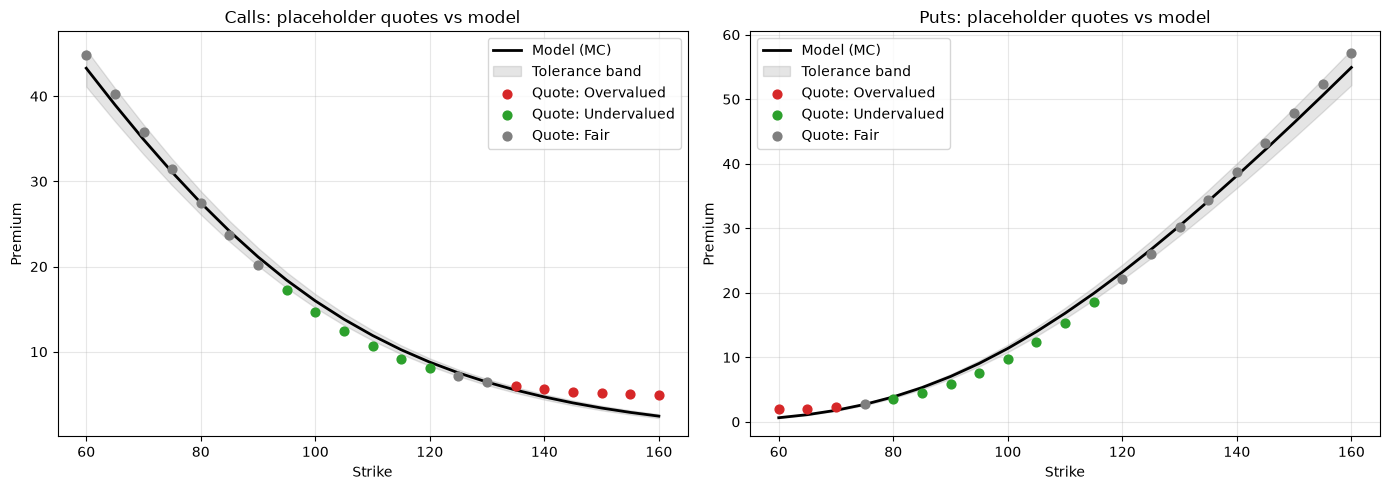

,kind,strike,mc_price,std_error,market_price,signal,gap,band,gap_pct
0,call,60.0000,43.2863,0.3540,44.8597,Fair,1.5735,2.1643,0.0363
1,call,65.0000,39.0040,0.3485,40.2344,Fair,1.2303,1.9502,0.0315
2,call,70.0000,34.9258,0.3412,35.7590,Fair,0.8333,1.7463,0.0239
3,call,75.0000,31.0807,0.3323,31.4689,Fair,0.3882,1.5540,0.0125
4,call,80.0000,27.4876,0.3219,27.4127,Fair,-0.0749,1.3744,-0.0027
5,call,85.0000,24.1674,0.3102,23.6481,Fair,-0.5193,1.2084,-0.0215
6,call,90.0000,21.1376,0.2974,20.2327,Fair,-0.9050,1.0569,-0.0428
7,call,95.0000,18.4074,0.2837,17.2120,Undervalued,-1.1954,0.9204,-0.0649
8,call,100.0000,15.9738,0.2693,14.6107,Undervalued,-1.3631,0.7987,-0.0853
9,call,105.0000,13.8210,0.2545,12.4272,Undervalued,-1.3938,0.6911,-0.1008


In [12]:
def flag_mispricing(model_price, std_error, market_price, z=1.96, rel_tol=0.05):
    """Classify a market quote against a model price.

    'Overvalued'  : market premium is above the model band, so the option looks expensive
    'Undervalued' : market premium is below the model band, so the option looks cheap
    'Fair'        : within noise / tolerance
    """
    band = np.maximum(z * np.asarray(std_error), rel_tol * np.asarray(model_price))
    gap = np.asarray(market_price) - np.asarray(model_price)
    return np.where(gap > band, "Overvalued", np.where(gap < -band, "Undervalued", "Fair")), gap, band


# --- PLACEHOLDER quotes: Black-Scholes with a made-up smile, sigma(K) = sigma + 0.6 * ln(K/S0)^2 - 0.04 ---
def placeholder_market_quote(kind, k):
    smile_vol = sigma + 0.6 * np.log(k / S0) ** 2 - 0.04
    pricer = black_scholes_call if kind == "call" else black_scholes_put
    return pricer(S0, k, T, r, smile_vol)

valuation = chain[["kind", "strike", "mc_price", "std_error"]].copy()
valuation["market_price"] = [placeholder_market_quote(kd, k) for kd, k in zip(valuation.kind, valuation.strike)]
valuation["signal"], valuation["gap"], valuation["band"] = flag_mispricing(
    valuation.mc_price, valuation.std_error, valuation.market_price
)
valuation["gap_pct"] = valuation.gap / valuation.mc_price

colors = {"Overvalued": "tab:red", "Undervalued": "tab:green", "Fair": "tab:grey"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, kind in zip(axes, ("call", "put")):
    sub = valuation[valuation.kind == kind]
    ax.plot(sub.strike, sub.mc_price, "k-", linewidth=2, label="Model (MC)")
    ax.fill_between(sub.strike, sub.mc_price - sub.band, sub.mc_price + sub.band, color="black", alpha=0.1, label="Tolerance band")
    for signal, color in colors.items():
        pts = sub[sub.signal == signal]
        ax.scatter(pts.strike, pts.market_price, color=color, s=40, zorder=3, label=f"Quote: {signal}")
    ax.set(title=f"{kind.title()}s: placeholder quotes vs model", xlabel="Strike", ylabel="Premium")
    ax.legend()
plt.tight_layout()
plt.show()

valuation.round(4)

## 4. Risk Assessment: Portfolio Value at Risk

**VaR at confidence $\alpha$** is the loss that is exceeded only with probability $1-\alpha$ over a horizon $h$:
$\text{VaR}_\alpha = -\,\text{quantile}_{1-\alpha}(\text{P\&L})$.
**CVaR / Expected Shortfall** is the *average* loss on the days that are worse than VaR, which tells you how bad the tail is.

Two modelling points:

- **Use a real-world drift $\mu$, not $r$.** Pricing uses the risk-neutral measure, but risk is about what actually happens.
  The `src` simulators take the drift as their `r` argument, so we just pass $\mu$ in.
- **Revalue the options at the horizon.** At $h$ the puts still have $T-h$ left, so we reprice them with Black–Scholes on every scenario
  (full revaluation, not a delta approximation).

Two portfolios are compared: **unhedged** (1,000 shares) and **protective put** (1,000 shares + 1,000 puts at $K=90$).

In [13]:
MU = 0.08                    # real-world annual drift (assumption)
HORIZON_DAYS = 10
h = HORIZON_DAYS / 252
N_SHARES = 1_000
N_PUTS = 1_000
K_PUT = 90.0
CONFIDENCE = [0.95, 0.99]

# Scenario prices at the horizon under the real-world measure
S_h = simulate_terminal_prices(S0, MU, sigma, h, N_TERMINAL, rng=np.random.default_rng(SEED + 1))

# Full revaluation of the puts with remaining maturity T - h
put_today = black_scholes_put(S0, K_PUT, T, r, sigma)
put_at_h = np.array([black_scholes_put(s, K_PUT, T - h, r, sigma) for s in S_h])

V0_stock = N_SHARES * S0
pnl_stock = N_SHARES * (S_h - S0)
V0_hedged = V0_stock + N_PUTS * put_today
pnl_hedged = pnl_stock + N_PUTS * (put_at_h - put_today)


def var_cvar(pnl, alpha):
    var = -np.quantile(pnl, 1 - alpha)
    cvar = -pnl[pnl <= -var].mean()
    return var, cvar


def analytic_stock_var(value, mu, sigma, h, alpha):
    """Exact lognormal VaR for a pure stock position."""
    worst_return = np.exp((mu - 0.5 * sigma**2) * h + sigma * np.sqrt(h) * stats.norm.ppf(1 - alpha)) - 1
    return -value * worst_return


risk_rows = []
for alpha in CONFIDENCE:
    v_s, c_s = var_cvar(pnl_stock, alpha)
    v_h, c_h = var_cvar(pnl_hedged, alpha)
    risk_rows += [
        {"portfolio": "Unhedged", "confidence": f"{alpha:.0%}", "VaR (MC)": v_s, "CVaR (MC)": c_s,
         "VaR (analytic)": analytic_stock_var(V0_stock, MU, sigma, h, alpha), "VaR % of value": v_s / V0_stock},
        {"portfolio": "Protective put", "confidence": f"{alpha:.0%}", "VaR (MC)": v_h, "CVaR (MC)": c_h,
         "VaR (analytic)": np.nan, "VaR % of value": v_h / V0_hedged},
    ]
print(f"Horizon: {HORIZON_DAYS} trading days | μ = {MU:.0%}, σ = {sigma:.0%} | put premium paid = {N_PUTS * put_today:,.0f}")
risk_table = pd.DataFrame(risk_rows).set_index(["portfolio", "confidence"])
risk_table.style.format({c: "{:,.0f}" for c in ["VaR (MC)", "CVaR (MC)", "VaR (analytic)"]} | {"VaR % of value": "{:.2%}"}, na_rep="–")

Horizon: 10 trading days | μ = 8%, σ = 35% | put premium paid = 6,932


,,VaR (MC),CVaR (MC),VaR (analytic),VaR % of value
portfolio,confidence,,,,
Unhedged,95%,"10,919","13,328","10,769",10.92%
Protective put,95%,"7,524","8,932",–,7.04%
Unhedged,99%,"14,850","16,636","14,909",14.85%
Protective put,99%,"9,826","10,787",–,9.19%


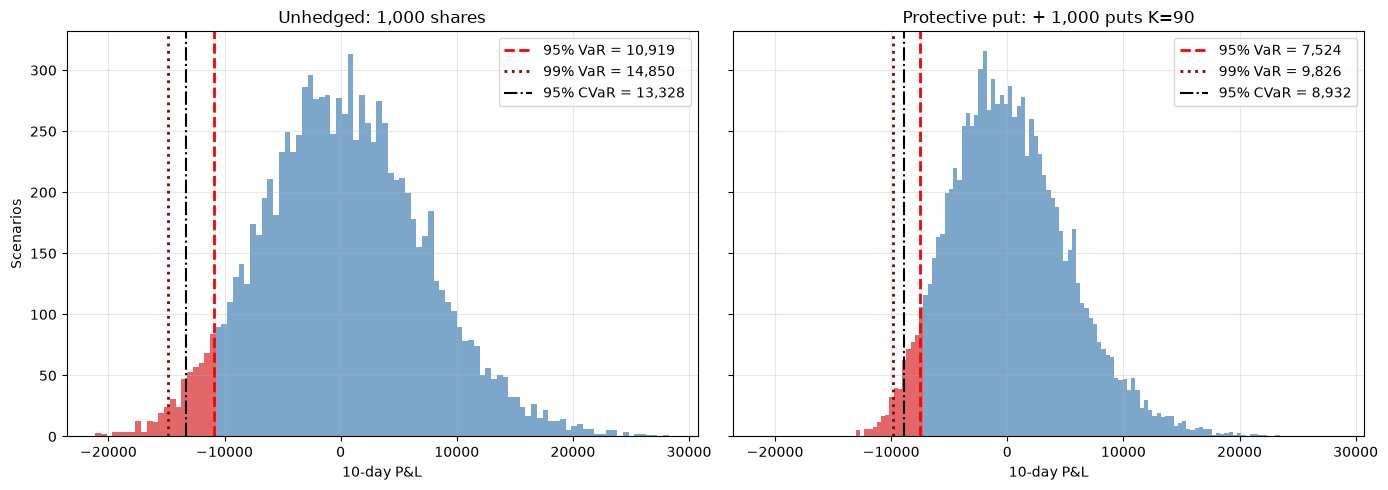

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, (name, pnl) in zip(axes, [("Unhedged: 1,000 shares", pnl_stock), ("Protective put: + 1,000 puts K=90", pnl_hedged)]):
    var95, cvar95 = var_cvar(pnl, 0.95)
    var99, _ = var_cvar(pnl, 0.99)
    counts, bins, patches = ax.hist(pnl, bins=100, color="steelblue", alpha=0.7)
    for patch, left in zip(patches, bins[:-1]):
        if left < -var95:
            patch.set_facecolor("tab:red")
    ax.axvline(-var95, color="red", linestyle="--", linewidth=2, label=f"95% VaR = {var95:,.0f}")
    ax.axvline(-var99, color="darkred", linestyle=":", linewidth=2, label=f"99% VaR = {var99:,.0f}")
    ax.axvline(-cvar95, color="black", linestyle="-.", linewidth=1.5, label=f"95% CVaR = {cvar95:,.0f}")
    ax.set(title=name, xlabel=f"{HORIZON_DAYS}-day P&L")
    ax.legend()
axes[0].set_ylabel("Scenarios")
plt.tight_layout()
plt.show()

### VaR across horizons

For a pure stock position, VaR grows roughly like $\sqrt{h}$, the same square-root law as the spaghetti fan.
The Monte Carlo estimate should track the closed form across horizons, and the put caps how fast the hedged VaR can grow.

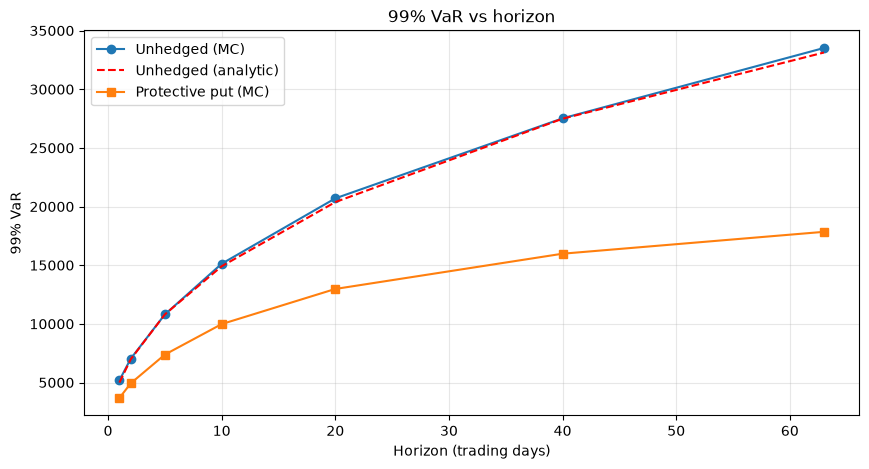

,Unhedged (MC),Unhedged (analytic),Protective put (MC)
days,,,
1,"5,186.0000","4,993.0000","3,679.0000"
2,"7,032.0000","6,983.0000","4,931.0000"
5,"10,802.0000","10,803.0000","7,378.0000"
10,"15,123.0000","14,909.0000","9,979.0000"
20,"20,697.0000","20,379.0000","12,975.0000"
40,"27,519.0000","27,488.0000","15,980.0000"
63,"33,516.0000","33,130.0000","17,844.0000"


In [15]:
horizons = np.array([1, 2, 5, 10, 20, 40, 63])
alpha = 0.99
curve = []
for days in horizons:
    hh = days / 252
    s_h = simulate_terminal_prices(S0, MU, sigma, hh, N_TERMINAL, rng=np.random.default_rng(int(days)))
    p_stock = N_SHARES * (s_h - S0)
    p_put = np.array([black_scholes_put(s, K_PUT, T - hh, r, sigma) for s in s_h])
    p_hedged = p_stock + N_PUTS * (p_put - put_today)
    curve.append({
        "days": days,
        "Unhedged (MC)": var_cvar(p_stock, alpha)[0],
        "Unhedged (analytic)": analytic_stock_var(V0_stock, MU, sigma, hh, alpha),
        "Protective put (MC)": var_cvar(p_hedged, alpha)[0],
    })
curve = pd.DataFrame(curve).set_index("days")

ax = curve.plot(style=["o-", "r--", "s-"], figsize=(10, 5))
ax.set(xlabel="Horizon (trading days)", ylabel=f"{alpha:.0%} VaR", title=f"{alpha:.0%} VaR vs horizon")
plt.show()
curve.round(0)

## 5. Summary and next steps

| Check | What we expect | Where |
|---|---|---|
| Path dispersion | $\operatorname{sd}(\ln S_t)$ follows $\sigma\sqrt t$ | §1 |
| Terminal distribution | Histogram matches the lognormal pdf, mode < median < mean | §2 |
| MC vs Black–Scholes | BS inside the MC 95% CI for most strikes | §3.2 |
| Convergence | RMSE follows the $1/\sqrt N$ line | §3.3 |
| Stock VaR | MC matches the analytic lognormal VaR | §4 |

**To plug in live data later:**
- `S0` from the spot price; `sigma` from historical returns (or implied vol per strike); `r` from a treasury yield
- Replace `placeholder_market_quote` with the real option chain (mid price) and expiries in years
- `MU` estimated from history, or set conservatively to 0 for risk work

**Candidates to move into `src/`** for the Streamlit app: `mc_price_with_ci`, `flag_mispricing`, `var_cvar`, `analytic_stock_var`.